# **DS - Les 6 - Customer Churn**
## **Les: End-to-End Customer Churn Prediction & Model Evaluation**
  
**Doelstelling**
- Data Wrangling: Werken met relationele data, joins/merges en inconsistenties in sleutels (case sensitivity).
- Feature Engineering & Preprocessing: Opzetten van een lekvrije scikit-learn pipeline met ColumnTransformer.
- Class Imbalance & Modelvergelijking: Trainen en vergelijken van Tree Ensembles (Random Forest, AdaBoost, XGBoost) en Support Vector Machines (SVM).
- Metrieken voor Churn: Begrijpen waarom Accuracy misleidend is, en hoe ROC-AUC, Precision-Recall, en F1-score gekoppeld worden aan businesswaarde (retentiekosten vs. misgelopen inkomsten).
- Productie-gereedheid: Modeltraining encapsuleren in een herbruikbare, parametriseerbare functie en inferentie uitvoeren op nieuwe klanten.

## **Stap 1:** Libraries

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

import pandas as pd
import numpy as np
import seaborn as sns
import os

In [11]:
os.getcwd()

'C:\\Users\\u0169599\\OneDrive - Thomas More\\Data Science Course\\3e bach - Machine Learning\\datasets'

## **Stap 2:** Data

In [22]:
df_abonnement = pd.read_csv("abonnement_info.csv")
print(df_abonnement.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   CustomerID        7043 non-null   object
 1   gender            7043 non-null   object
 2   SeniorCitizen     7043 non-null   int64 
 3   Partner           7043 non-null   object
 4   Dependents        7043 non-null   object
 5   tenure            7043 non-null   int64 
 6   PhoneService      7043 non-null   object
 7   MultipleLines     7043 non-null   object
 8   InternetService   7043 non-null   object
 9   OnlineSecurity    7043 non-null   object
 10  OnlineBackup      7043 non-null   object
 11  DeviceProtection  7043 non-null   object
 12  TechSupport       7043 non-null   object
 13  StreamingTV       7043 non-null   object
 14  StreamingMovies   7043 non-null   object
 15  Contract          7043 non-null   object
 16  PaperlessBilling  7043 non-null   object
dtypes: int64(2), o

In [23]:
df_payment_features = pd.read_csv("betalingen_features.csv")
df_payment_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      7043 non-null   object 
 1   PaymentMethod   7043 non-null   object 
 2   MonthlyCharges  7043 non-null   float64
 3   TotalCharges    7043 non-null   object 
 4   card_number     7043 non-null   object 
dtypes: float64(1), object(4)
memory usage: 275.2+ KB


In [24]:
df_churn_lables = pd.read_csv("klanten_churn.csv")
df_churn_lables.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   card_number  7043 non-null   object
 1   Churn        7043 non-null   object
dtypes: object(2)
memory usage: 110.2+ KB


In [28]:
# Stap 1: Normaliseer CustomerID 

# Stap 2: Koppel abonnement en payment features via CustomerID_clean

# Stap 3: Koppel churn labels via card_number
df_complete = ...

df_complete.head(10)


,CustomerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,CustomerID_clean,PaymentMethod,MonthlyCharges,TotalCharges,card_number,Churn
0,BE-25795E,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,be-25795e,Electronic check,29.85,29.85,****127276,No
1,BE-86820B,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,be-86820b,Mailed check,56.95,1889.5,****582526,No
2,BE-92386C,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,be-92386c,Mailed check,53.85,108.15,****181894,Yes
3,BE-97498E,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,be-97498e,Bank transfer (automatic),42.30,1840.75,****553311,No
4,BE-54131C,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,be-54131c,Electronic check,70.70,151.65,****314231,Yes
5,BE-77221E,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,be-77221e,Electronic check,99.65,820.5,****634973,Yes
6,BE-10769D,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,Yes,No,Month-to-month,Yes,be-10769d,Credit card (automatic),89.10,1949.4,****811065,No
7,BE-74925F,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,Month-to-month,No,be-74925f,Mailed check,29.75,301.9,****871783,No
8,BE-77969D,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,be-77969d,Electronic check,104.80,3046.05,****562802,Yes
9,BE-93104D,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,One year,No,be-93104d,Bank transfer (automatic),56.15,3487.95,****669621,No


In [29]:
# Stap 4: Opschonen van features identificatoren op die niet bijdragen aan modellering
...


       SeniorCitizen       tenure  MonthlyCharges
count    7145.000000  7145.000000     7145.000000
mean        0.161931    32.332680       64.735717
std         0.368414    24.534536       30.071956
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.550000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7145 entries, 0 to 7144
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7145 non-null   object 
 1   SeniorCitizen     7145 non-null   int64  
 2   Partner           7145 non-null   object 
 3   Dependents        7145 non-null   object 
 4   tenure            7145 non-null   int64  
 5   PhoneService      7145 non-null   object 
 6   MultipleLines     7145 non-null   object 
 7   InternetService

In [30]:
# Stap 5: Type casting en missing value inspectie
# "TotalCharges" bevat vaak verborgen spaties (' ') bij nieuwe klanten (tenure = 0)


# Encodeer Churn naar numeriek (1 = Ja, 0 = Nee)


print(f"Gereconstrueerde dataset vorm: {df_complete.shape}")
print(f"Churn verdeling:\n{df_complete[churn_target].value_counts(normalize=True)}")

Gereconstrueerde dataset vorm: (7145, 20)
Churn verdeling:
Churn
0    0.73366
1    0.26634
Name: proportion, dtype: float64


## **Stap 3:** Preprocessing en Train Test Split
  
- Om data leakage te vermijden, definiëren we numerieke en categorische transformaties via ColumnTransformer. 
- De numerieke features worden geschaald (essentieel voor SVM) en categorische variabelen worden one-hot encoded.

In [33]:
# Features (X) en target (y)
X = 
y = 

# Train-test split (stratified wegens class imbalance!!)

print(f"Omvang trainingset: {X_train.shape[0]} | Omvang testset: {X_test.shape[0]}")

Omvang trainingset: 5716 | Omvang testset: 1429


In [34]:
# Identificeer kolomtypen
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# Preprocessing sub-pipelines
numeric_transformer = ...

categorical_transformer = ...

preprocessor = ...

## **Stap 4:** ML Pipeline

In [35]:
# Modellen definiëren
models = {
    "Random Forest": RandomForestClassifier(...),
    "AdaBoost": AdaBoostClassifier(...),
    "XGBoost": XGBClassifier(...),
    "SVM (RBF)": SVC(...),
}

## **Stap 5:** Training en evaluatie

In [36]:
# Training en evaluatie
results = {}
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(...)
    pipe.fit(...)

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results[name] = {
        "Accuracy": ...,
        "Precision": ...,
        "Recall": ...,
        "F1-Score": ...,
        "ROC-AUC": ...,
        "y_proba": y_proba,
    }
    trained_pipelines[name] = pipe

# Vergelijkingstabel
df_metrics = pd.DataFrame(results).T.drop(columns=["y_proba"])
print(df_metrics.round(3))

               Accuracy Precision    Recall  F1-Score   ROC-AUC
Random Forest  0.773268  0.551351   0.80315  0.653846  0.851965
AdaBoost       0.795661  0.665428  0.469816  0.550769   0.84209
XGBoost        0.741078  0.508914  0.824147  0.629259  0.847342
SVM (RBF)      0.748076  0.517529  0.813648  0.632653   0.83845


### **ROC & AUC in de Context van Churn**
#### *1. Waarom geen "Accuracy?"*
...

#### *2. Wat toont de ROC-Curve?*
...

#### *3. De Bedrijfsmatige Vertaling van de Drempelwaarde (Threshold)*
...

#### *4. Area Under the Curve (AUC)*
...

### **Visualisatie van de ROC-Curven**

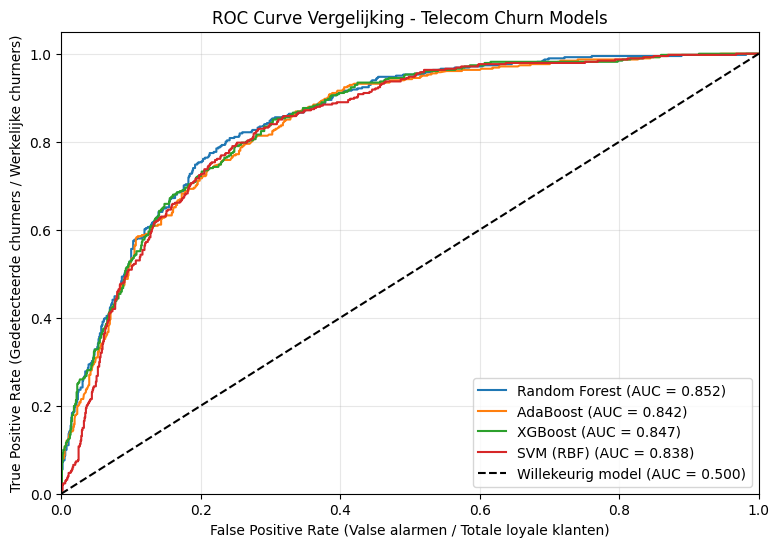

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
    roc_score = res["ROC-AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_score:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Willekeurig model (AUC = 0.500)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (Valse alarmen / Totale loyale klanten)")
plt.ylabel("True Positive Rate (Gedetecteerde churners / Werkelijke churners)")
plt.title("ROC Curve Vergelijking - Telecom Churn Models")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

## **Stap 6:** Predictie

Predictie voor een Nieuwe Klant
We simuleren een nieuwe klant die binnenstroomt via een CRM-formulier en sturen deze door onze best presterende pipeline.

In [38]:
best_model_name = df_metrics["ROC-AUC"].astype(float).idxmax()
best_pipeline = trained_pipelines[best_model_name]
print(f"Beste model op basis van ROC-AUC: {best_model_name}")

# Gegevens van een nieuwe, binnenkomende klant
nieuwe_klant = pd.DataFrame(
    [
        {
            "gender": "Female",
            "SeniorCitizen": 0,
            "Partner": "No",
            "Dependents": "No",
            "tenure": 2,  # Slechts 2 maanden klant (hoog risico)
            "PhoneService": "Yes",
            "MultipleLines": "No",
            "InternetService": "Fiber optic",
            "OnlineSecurity": "No",
            "OnlineBackup": "No",
            "DeviceProtection": "No",
            "TechSupport": "No",
            "StreamingTV": "Yes",
            "StreamingMovies": "Yes",
            "Contract": "Month-to-month",  # Maandcontract (hoog risico)
            "PaperlessBilling": "Yes",
            "PaymentMethod": "Electronic check",
            "MonthlyCharges": 89.50,
            "TotalCharges": 179.0,
        }
    ]
)

# Voorspelling uitvoeren
churn_kans = best_pipeline.predict_proba(nieuwe_klant)[0, 1]
standaard_voorspelling = best_pipeline.predict(nieuwe_klant)[0]

print("\n--- Resultaat Nieuwe Klant ---")
print(f"Geschatte churn-waarschijnlijkheid: {churn_kans:.1%}")
print(f"Standaard classificatie (drempel 0.50): {'CHURN' if standaard_voorspelling == 1 else 'GEEN CHURN'}")

# Zakelijke interventie drempel op 0.35
business_threshold = 0.35
interventie = churn_kans >= business_threshold
print(f"Actie vereist (interventie-drempel {business_threshold:.2f}): {'JA, bied direct retentiepromo aan' if interventie else 'NEE'}")

Beste model op basis van ROC-AUC: Random Forest

--- Resultaat Nieuwe Klant ---
Geschatte churn-waarschijnlijkheid: 90.0%
Standaard classificatie (drempel 0.50): CHURN
Actie vereist (interventie-drempel 0.35): JA, bied direct retentiepromo aan


## **Vragen**

1. Data Leakage & Preprocessing: Waarom moeten StandardScaler en SimpleImputer worden opgenomen in de Pipeline in plaats van vooraf uitgevoerd te worden over de gehele samengevoegde dataset?

2. Business Trade-off bij Churn: Stel dat de telecomoperator beschikt over een callcenterteam dat maandelijks maximaal 200 risicoklanten kan opbellen om hen te overtuigen te blijven. Moet je dan optimaliseren op een hoge Recall of op een hoge Precision@Top-200? Waarom?

3. Hyperparameter Tuning: Wat is het effect van de parameter scale_pos_weight in XGBoost en class_weight='balanced' in Random Forest/SVM op de ROC-curve en de optimale beslissingsdrempel?

4. Data Integriteit: Welke risico's brengt het met zich mee als bij het samenvoegen van relationele databases de primary en foreign keys niet eerst gestandaardiseerd worden (zoals de hoofdletters in CustomerID)? Wat gebeurt er bij een inner join versus een left join?

# Oefening **Master Pipeline Functie**
In productieomgevingen wil je hyperparameters, modellen en selectie-strategieën flexibel aanroepen zonder herhalende code.

In [41]:
def run_churn_pipeline(
    df,
    target_col="Churn",
    model_type="xgboost",
    test_size=0.20,
    random_state=42,
    model_params=None,
):
    """
    Traint en evalueert een complete churn-pipeline op maat.
    """
    if model_params is None:
        model_params = {}

    # 1. Feature / target scheiding en split
    

    # 2. Preprocessing definitie
    

    # 3. Model selectie (initialiseer enkel het gekozen model)
   

    # 4. Pipeline assembleren en trainen


# Voorbeeld: Custom XGBoost aanroep
custom_pipeline, custom_metrics = run_churn_pipeline(
    df=df_complete,
    target_col="Churn",
    model_type="xgboost",
    model_params={
        "n_estimators": 150,
        "max_depth": 3,
        "learning_rate": 0.08,
        "scale_pos_weight": 2.5,
    },
)

Model     : XGBOOST
Accuracy  : 0.7628
Precision : 0.5379
Recall    : 0.7822
F1-Score  : 0.6374
ROC-AUC   : 0.8452
